In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re
from collections import Counter


df = pd.read_csv('../files/news.csv')
print(f"Размер датасета: {df.shape}")
print(df[['doc_id', 'title', 'source_topic']].head())
print("\nПропуски в данных:\n", df.isna().sum())


df['full_text'] = df['title'].fillna('') + ". " + df['text'].fillna('')

Размер датасета: (180, 6)
  doc_id                                              title source_topic
0   D001  ОПЕК сократила квоты на нефть. Аналитики ждут ...    Экономика
1   D002  "Русский Генеральный Банк" включен в реестр Го...    Экономика
2   D003  "Аэрофлот" и НРБ попросили Фрадкова отдать им ...    Экономика
3   D004       Минприроды решило не обижать "дочку" "ЮКОСа"    Экономика
4   D005       Евросоюз нанес удар по американскому импорту    Экономика

Пропуски в данных:
 doc_id          0
title           0
text            0
date            0
url             0
source_topic    0
dtype: int64


In [ ]:
import nltk
nltk.download('stopwords', quiet=True)

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www.\S+', '', text)
    text = re.sub(r'<.*?>', '', text)
    text = re.sub(r'\S+@\S+', '', text)
    text = re.sub(r'[^а-яё\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

df['cleaned_text'] = df['full_text'].apply(clean_text)


df['tokens'] = df['cleaned_text'].apply(lambda x: x.split())

print("Пример до обработки:\n", df['full_text'].iloc[0][:200])
print("\nПример после обработки:\n", df['cleaned_text'].iloc[0][:200])

Пример до обработки:
 ОПЕК сократила квоты на нефть. Аналитики ждут роста цен до 40 долларов за баррель. С 1 апреля Организация стран-экспортеров нефти (ОПЕК) снизила квоты на добычу нефти на миллион баррелей в сутки - с 2

Пример после обработки:
 опек сократила квоты на нефть аналитики ждут роста цен до долларов за баррель с апреля организация стран экспортеров нефти опек снизила квоты на добычу нефти на миллион баррелей в сутки с до миллиона 


In [ ]:
import pymorphy3
from nltk.corpus import stopwords


morph = pymorphy3.MorphAnalyzer()


russian_stopwords = set(stopwords.words('russian'))
russian_stopwords.discard('не')
russian_stopwords.discard('ни')
russian_stopwords.update(['год', 'также', 'сообщает', 'заявил', 'сказал', 'который', 'этот'])

def lemmatize(tokens):
    lemmas = []
    for token in tokens:
        if token not in russian_stopwords and len(token) > 2:
            p = morph.parse(token)[0]
            lemmas.append(p.normal_form)
    return lemmas

df['lemmas'] = df['tokens'].apply(lemmatize)

print("Пример лемм:\n", df['lemmas'].iloc[0][:15])

Пример лемм:
 ['опек', 'сократить', 'квота', 'нефть', 'аналитик', 'ждать', 'рост', 'цена', 'доллар', 'баррель', 'апрель', 'организация', 'страна', 'экспортёр', 'нефть']


Топ-20 слов:
год: 264
который: 204
компания: 159
матч: 155
время: 142
счёт: 131
первый: 127
мир: 123
россия: 121
свой: 121
команда: 118
доллар: 115
это: 103
чемпионат: 85
российский: 82
минута: 82
новый: 81
миллион: 78
процент: 77
сборная: 75


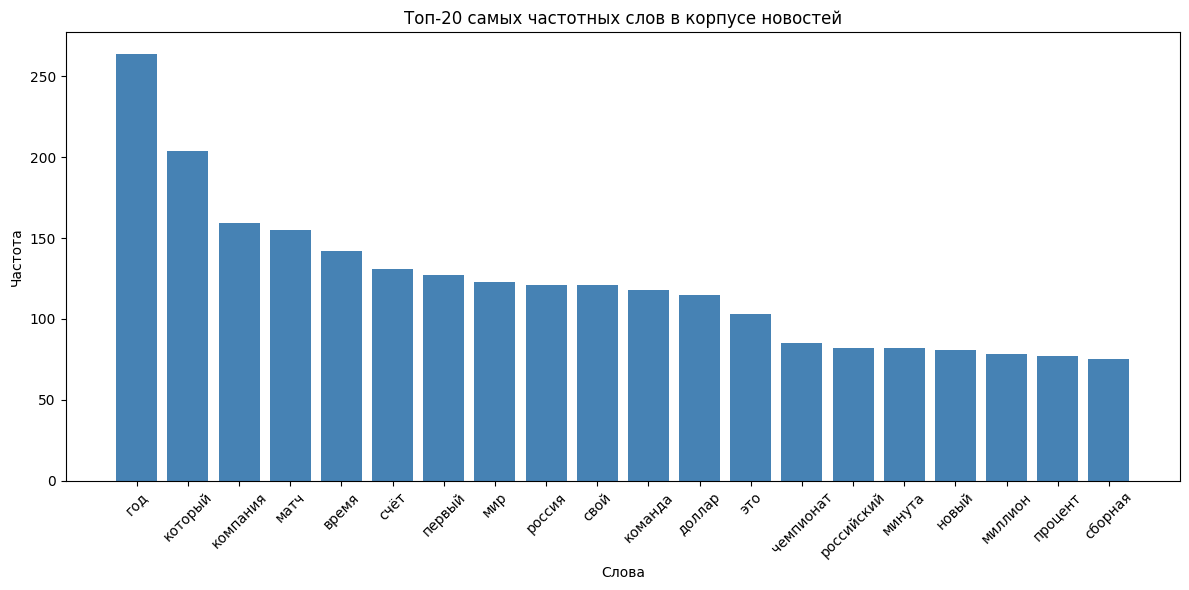

In [ ]:
all_words = [word for sublist in df['lemmas'] for word in sublist]
word_counts = Counter(all_words)
top_20 = word_counts.most_common(20)

print("Топ-20 слов:")
for word, count in top_20:
    print(f"{word}: {count}")


words, counts = zip(*top_20)
plt.figure(figsize=(12, 6))
plt.bar(words, counts, color='steelblue')
plt.xticks(rotation=45)
plt.title('Топ-20 самых частотных слов в корпусе новостей')
plt.ylabel('Частота')
plt.xlabel('Слова')
plt.tight_layout()
plt.show()

Распределение тональности:
sentiment
Позитивный     77
Нейтральный    71
Негативный     32
Name: count, dtype: int64


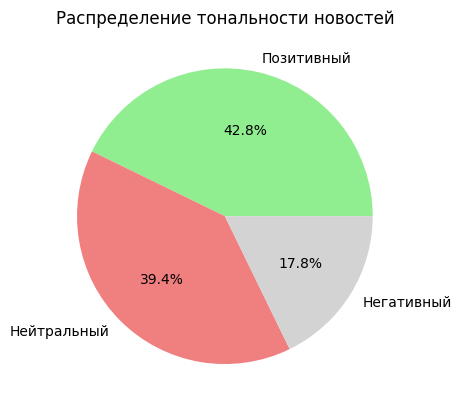

In [ ]:
positive_words = {'рост', 'успех', 'победа', 'выиграть', 'увеличить', 'развитие', 'улучшить', 'помощь', 'поддержка', 'хороший', 'лучший', 'рекорд', 'прибыль'}
negative_words = {'падение', 'проиграть', 'кризис', 'авария', 'ущерб', 'проблема', 'сократить', 'уволить', 'катастрофа', 'плохой', 'хуже', 'убыток', 'скандал', 'трагедия'}

def get_sentiment(lemmas):
    pos_count = sum(1 for word in lemmas if word in positive_words)
    neg_count = sum(1 for word in lemmas if word in negative_words)
    
    if pos_count > neg_count:
        return 'Позитивный'
    elif neg_count > pos_count:
        return 'Негативный'
    else:
        return 'Нейтральный'

df['sentiment'] = df['lemmas'].apply(get_sentiment)

print("Распределение тональности:")
print(df['sentiment'].value_counts())


df['sentiment'].value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['lightgreen', 'lightcoral', 'lightgray'])
plt.title('Распределение тональности новостей')
plt.ylabel('')
plt.show()

In [ ]:
from natasha import (
    Segmenter,
    MorphVocab,
    NewsEmbedding,
    NewsMorphTagger,
    NewsSyntaxParser,
    NewsNERTagger,
    Doc
)


segmenter = Segmenter()
morph_vocab = MorphVocab()
emb = NewsEmbedding()
morph_tagger = NewsMorphTagger(emb)
syntax_parser = NewsSyntaxParser(emb)
ner_tagger = NewsNERTagger(emb)

def extract_entities(text):
    doc = Doc(text)
    doc.segment(segmenter)
    doc.tag_morph(morph_tagger)
    doc.parse_syntax(syntax_parser)
    doc.tag_ner(ner_tagger)
    
    
    entities = []
    for span in doc.spans:
        if span.type in ('PER', 'ORG', 'LOC'):
            entities.append(f"{span.text} ({span.type})")
    return list(set(entities)) 


df['entities'] = df['full_text'].iloc[:5].apply(extract_entities)

for idx, row in df.iloc[:3].iterrows():
    print(f"--- {row['title']} ---")
    print("Сущности:", row['entities'])

--- ОПЕК сократила квоты на нефть. Аналитики ждут роста цен до 40 долларов за баррель ---
Сущности: ['Reuters (ORG)', 'Вене (LOC)', 'Джордж Буш (PER)', 'ОПЕК (ORG)', 'США (LOC)', 'Организация стран-экспортеров нефти (ОПЕК) (ORG)', 'Скотт Макклеллан (PER)', 'Associated Press (ORG)', 'Макклеллан (PER)', 'Белого дома (LOC)']
--- "Русский Генеральный Банк" включен в реестр Государственного таможенного комитета ---
Сущности: ['Русский Генеральный Банк (ORG)', 'РГБ (ORG)', 'Российской Федерации (LOC)', 'Государственный таможенный комитет (ORG)', 'Профиль (ORG)', 'Александра Пономаренко (PER)', 'НАУФОР (ORG)', 'России (LOC)', 'АКБ "Русский Генеральный Банк (ORG)', 'Государственного таможенного комитета (ORG)']
--- "Аэрофлот" и НРБ попросили Фрадкова отдать им "Шереметьево-3" ---
Сущности: ['Шереметьевым (ORG)', 'Альфа-Шереметьево (ORG)', 'Шереметьево-2 (ORG)', 'Шереметьево-3 (ORG)', 'ОАО "Терминал" (ORG)', 'Фрадкова (PER)', 'Барановский (PER)', 'Ведомостей (ORG)', 'НРБ (ORG)', 'Ведомости (ORG

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report


X = df['cleaned_text']
y = df['source_topic']


vectorizer = TfidfVectorizer(max_features=5000)
X_vec = vectorizer.fit_transform(X)


X_train, X_test, y_train, y_test = train_test_split(X_vec, y, test_size=0.2, random_state=42)


clf = LogisticRegression(max_iter=1000)
clf.fit(X_train, y_train)


y_pred = clf.predict(X_test)

print("Отчет по классификации:")
print(classification_report(y_test, y_pred, zero_division=0))

# Пример предсказания для нового текста
new_text = "Акции компании выросли на 10 процентов после публикации отчета о прибыли."
new_text_cleaned = clean_text(new_text)
new_vec = vectorizer.transform([new_text_cleaned])
print(f"\nПример текста: '{new_text}'")
print(f"Предсказанная тема: {clf.predict(new_vec)[0]}")

Отчет по классификации:
                 precision    recall  f1-score   support

Наука и техника       1.00      0.92      0.96        12
          Спорт       1.00      1.00      1.00        12
      Экономика       0.92      1.00      0.96        12

       accuracy                           0.97        36
      macro avg       0.97      0.97      0.97        36
   weighted avg       0.97      0.97      0.97        36


Пример текста: 'Акции компании выросли на 10 процентов после публикации отчета о прибыли.'
Предсказанная тема: Экономика
